# Quokka-Sharp Encoding Optimization Report

This notebook compares the baseline CNF encoding with the opt-in local inverse-pair optimizer. It measures gate count, CNF variables, clauses, weighted variables, and CNF construction time. External WMC runtime is intentionally not included.

In [1]:
from pathlib import Path
import csv
from collections import defaultdict
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'benchmarks').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'benchmarks' / 'results' / 'encoding_optimization.csv'
if not RESULTS.exists():
    raise FileNotFoundError(f'Run benchmarks/encoding_optimization_benchmark.py first: {RESULTS}')

with RESULTS.open(encoding='utf-8', newline='') as stream:
    rows = list(csv.DictReader(stream))
rows = [row for row in rows if row['status'] == 'ok']
len(rows), RESULTS

(124,
 WindowsPath('c:/Users/lexinyi/Desktop/PhD/Quantum/Quokka#/Quokka-Sharp/benchmarks/results/encoding_optimization.csv'))

In [2]:
def as_int(row, key):
    return int(row[key])

def as_float(row, key):
    return float(row[key])

def grouped(metric):
    grouped_rows = defaultdict(list)
    for row in rows:
        grouped_rows[row['basis']].append((row['circuit'], as_float(row, metric)))
    return grouped_rows

for basis, values in grouped('gate_reduction').items():
    positive = [value for _, value in values if value > 0]
    print(basis, 'circuits:', len(values), 'mean gate reduction:', sum(value for _, value in values) / len(values), 'positive:', len(positive))

computational circuits: 62 mean gate reduction: 0.20967741935483872 positive: 13
pauli circuits: 62 mean gate reduction: 0.20967741935483872 positive: 13


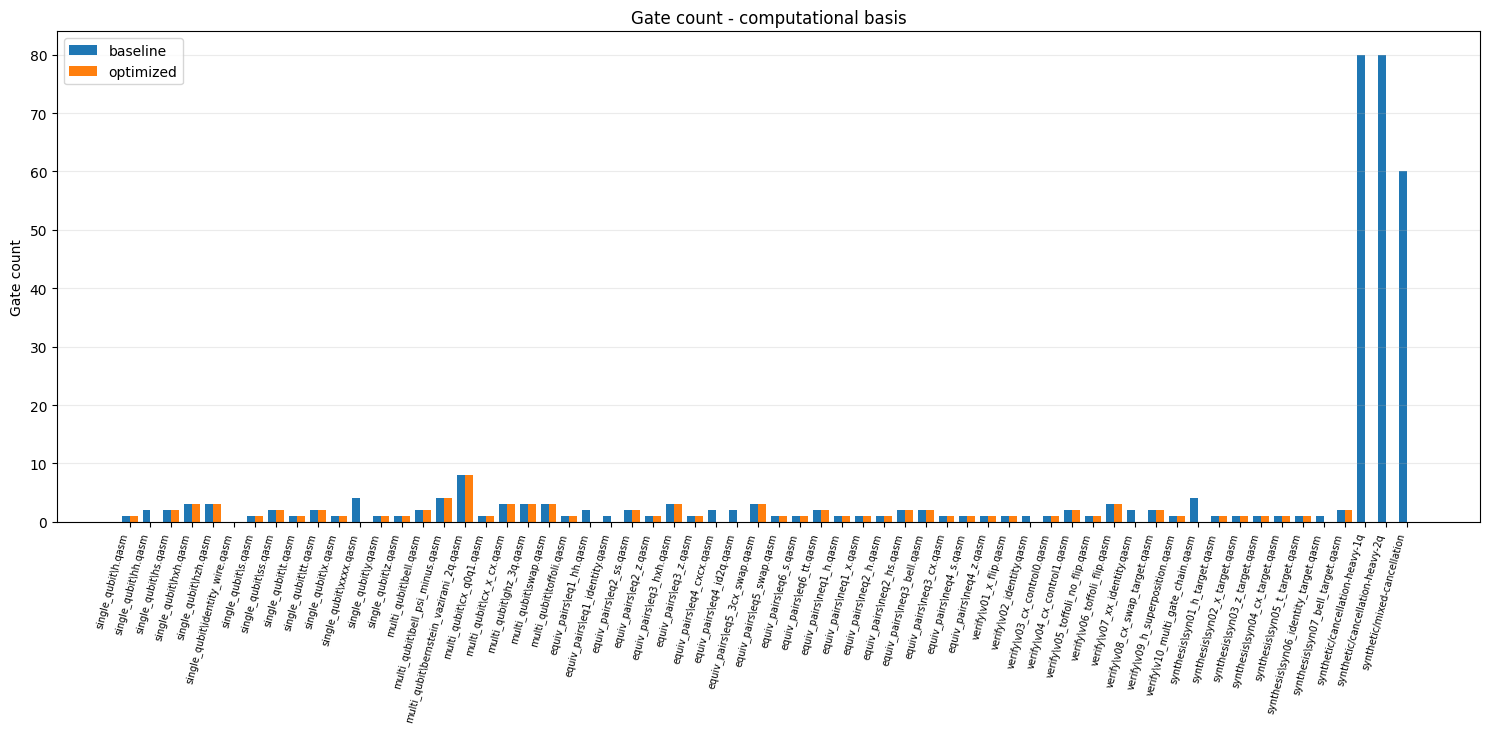

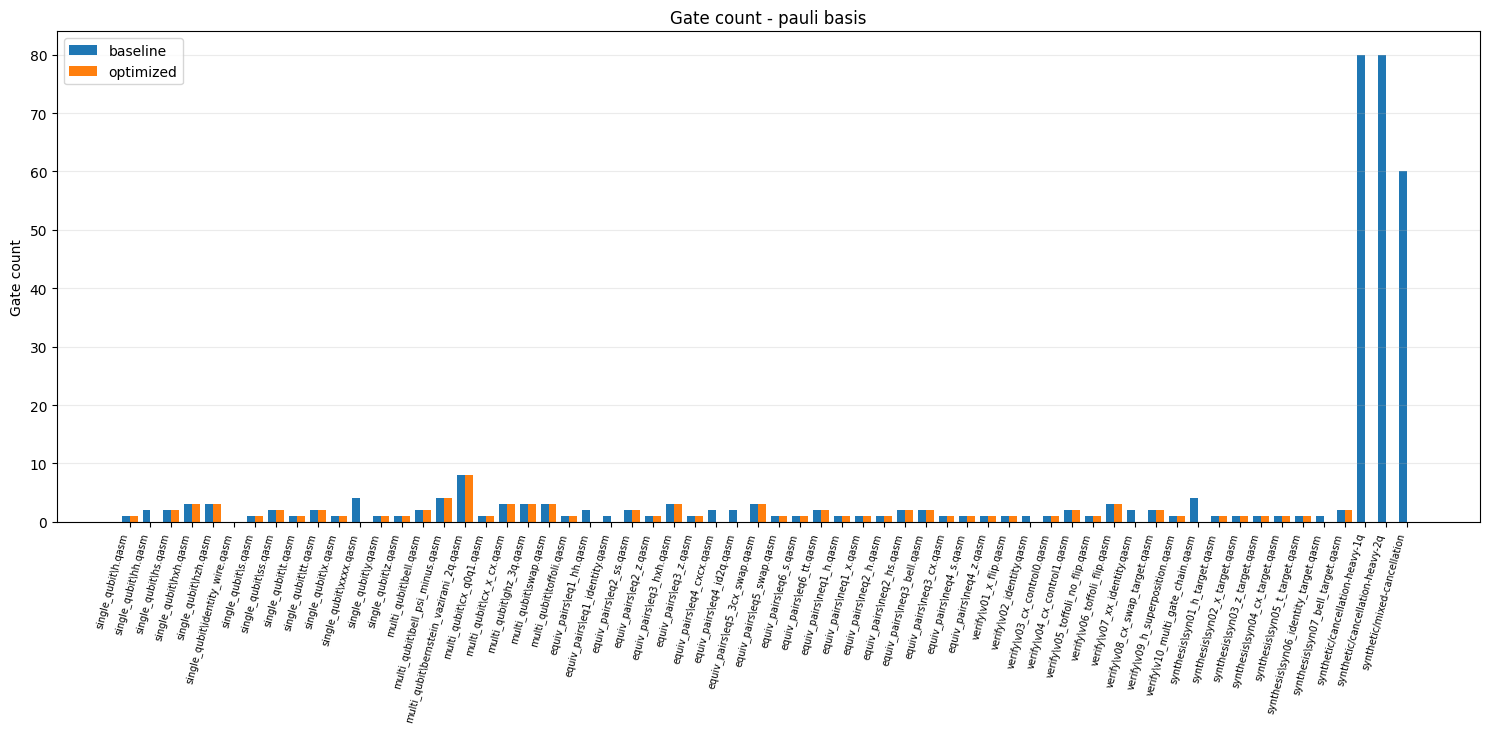

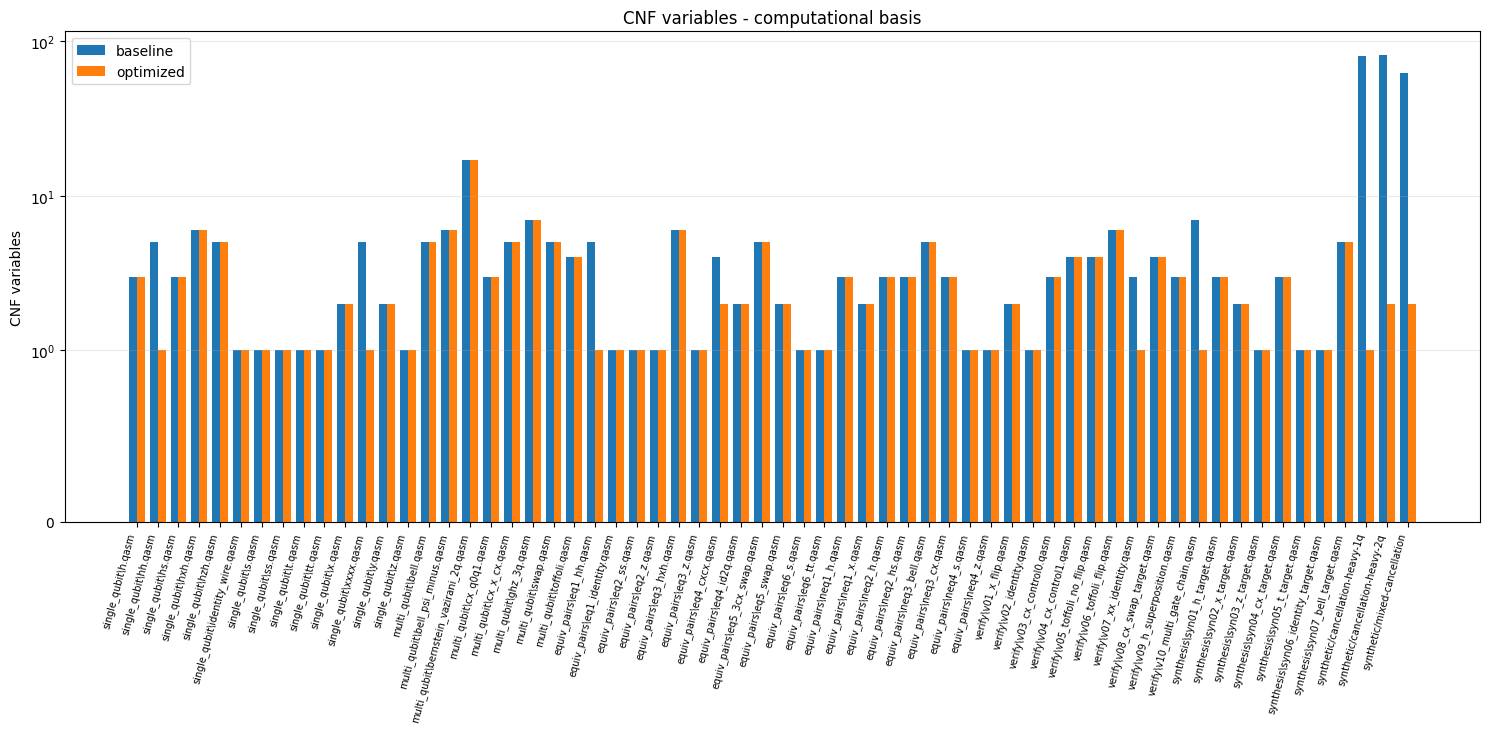

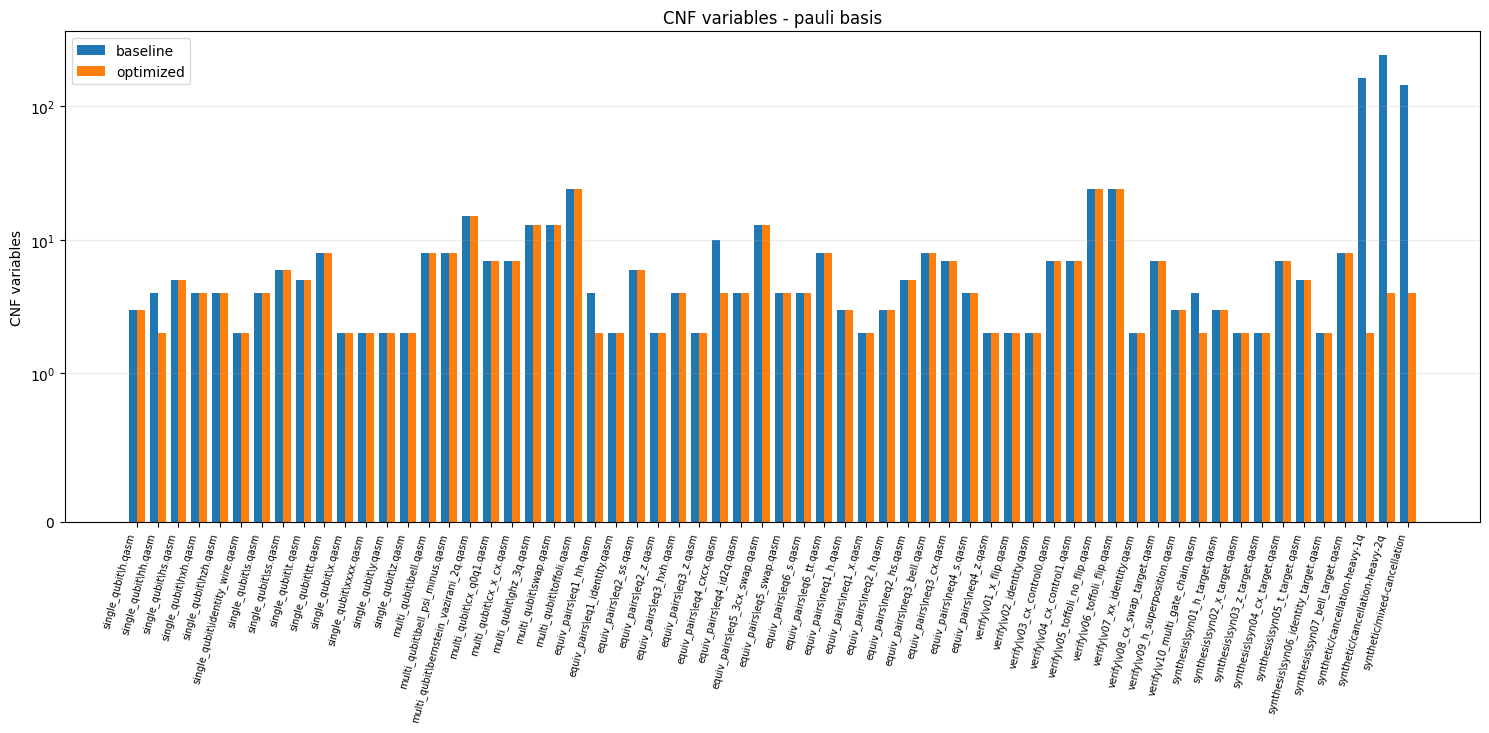

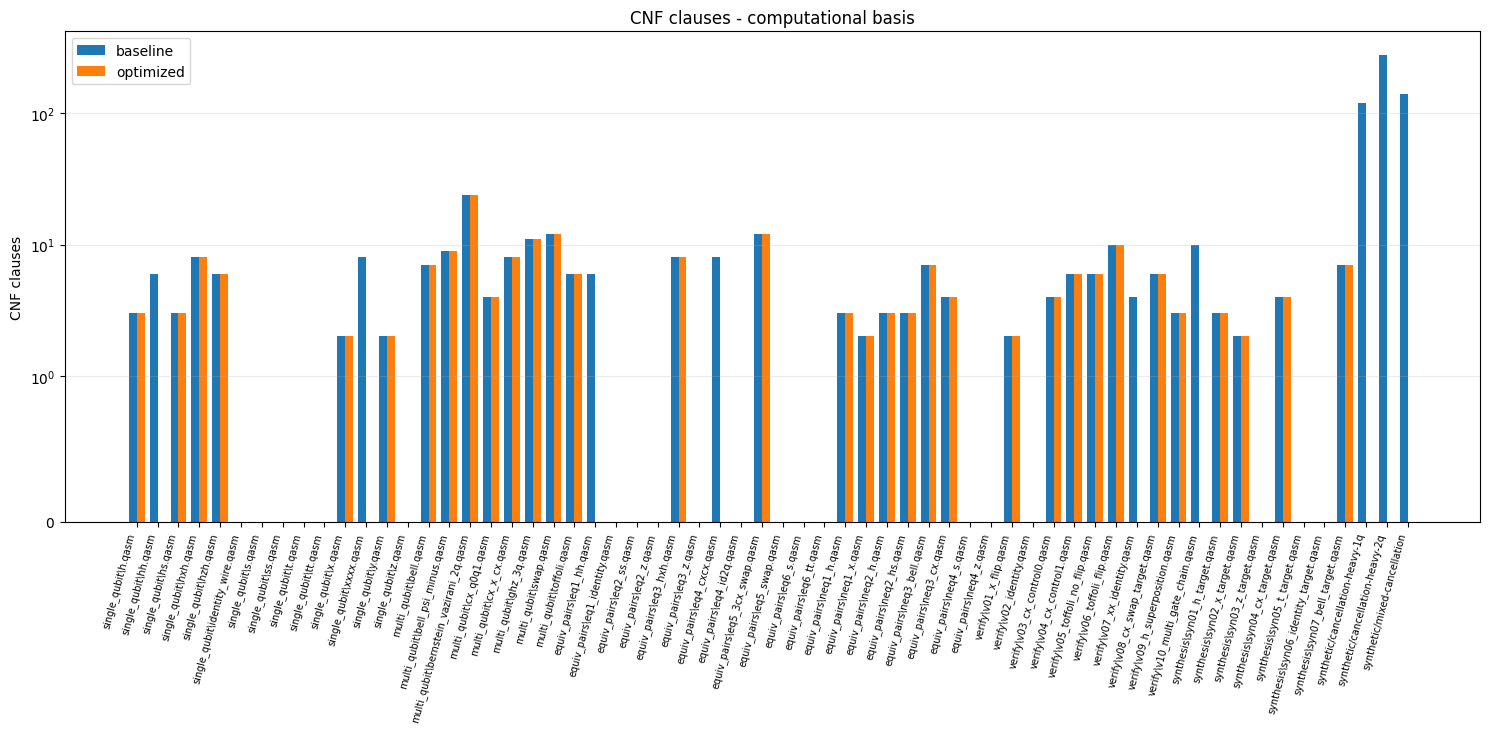

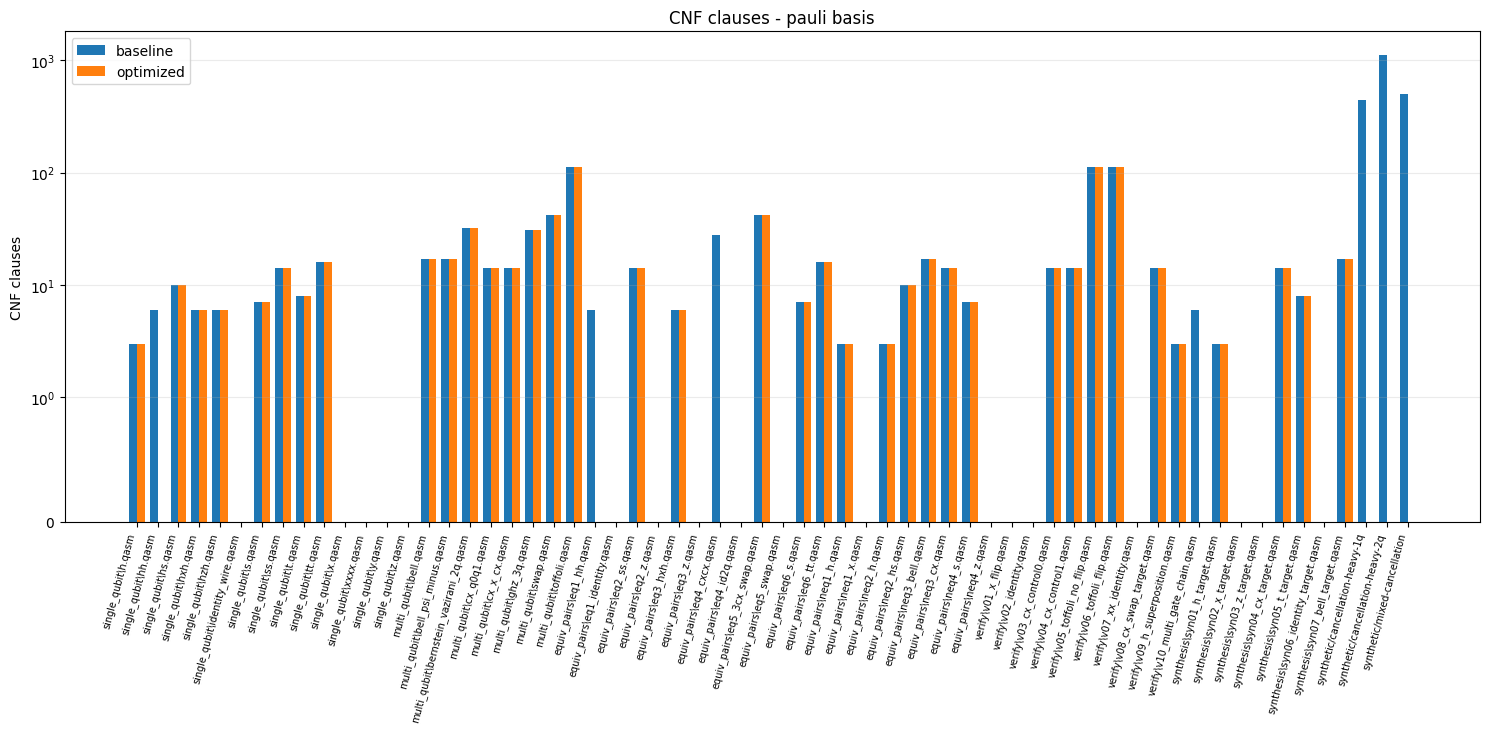

In [3]:
def paired_plot(original_key, optimized_key, title, log=False):
    for basis in sorted({row['basis'] for row in rows}):
        subset = [row for row in rows if row['basis'] == basis]
        labels = [row['circuit'] for row in subset]
        x = list(range(len(labels)))
        width = 0.38
        figure, axis = plt.subplots(figsize=(15, max(5, len(labels) * 0.12)))
        axis.bar([value - width / 2 for value in x], [as_int(row, original_key) for row in subset], width, label='baseline')
        axis.bar([value + width / 2 for value in x], [as_int(row, optimized_key) for row in subset], width, label='optimized')
        axis.set_title(f'{title} - {basis} basis')
        axis.set_ylabel(title)
        if log:
            axis.set_yscale('symlog', linthresh=1)
        axis.set_xticks(x)
        axis.set_xticklabels(labels, rotation=75, ha='right', fontsize=7)
        axis.grid(axis='y', alpha=0.25)
        axis.legend()
        figure.tight_layout()
        plt.show()

paired_plot('original_gates', 'optimized_gates', 'Gate count')
paired_plot('original_variables', 'optimized_variables', 'CNF variables', log=True)
paired_plot('original_clauses', 'optimized_clauses', 'CNF clauses', log=True)

C:\Users\lexinyi\AppData\Local\Temp\ipykernel_26516\3527447884.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[-1].set_xticklabels([row['circuit'] for row in rows[::2]], rotation=75, ha='right', fontsize=7)


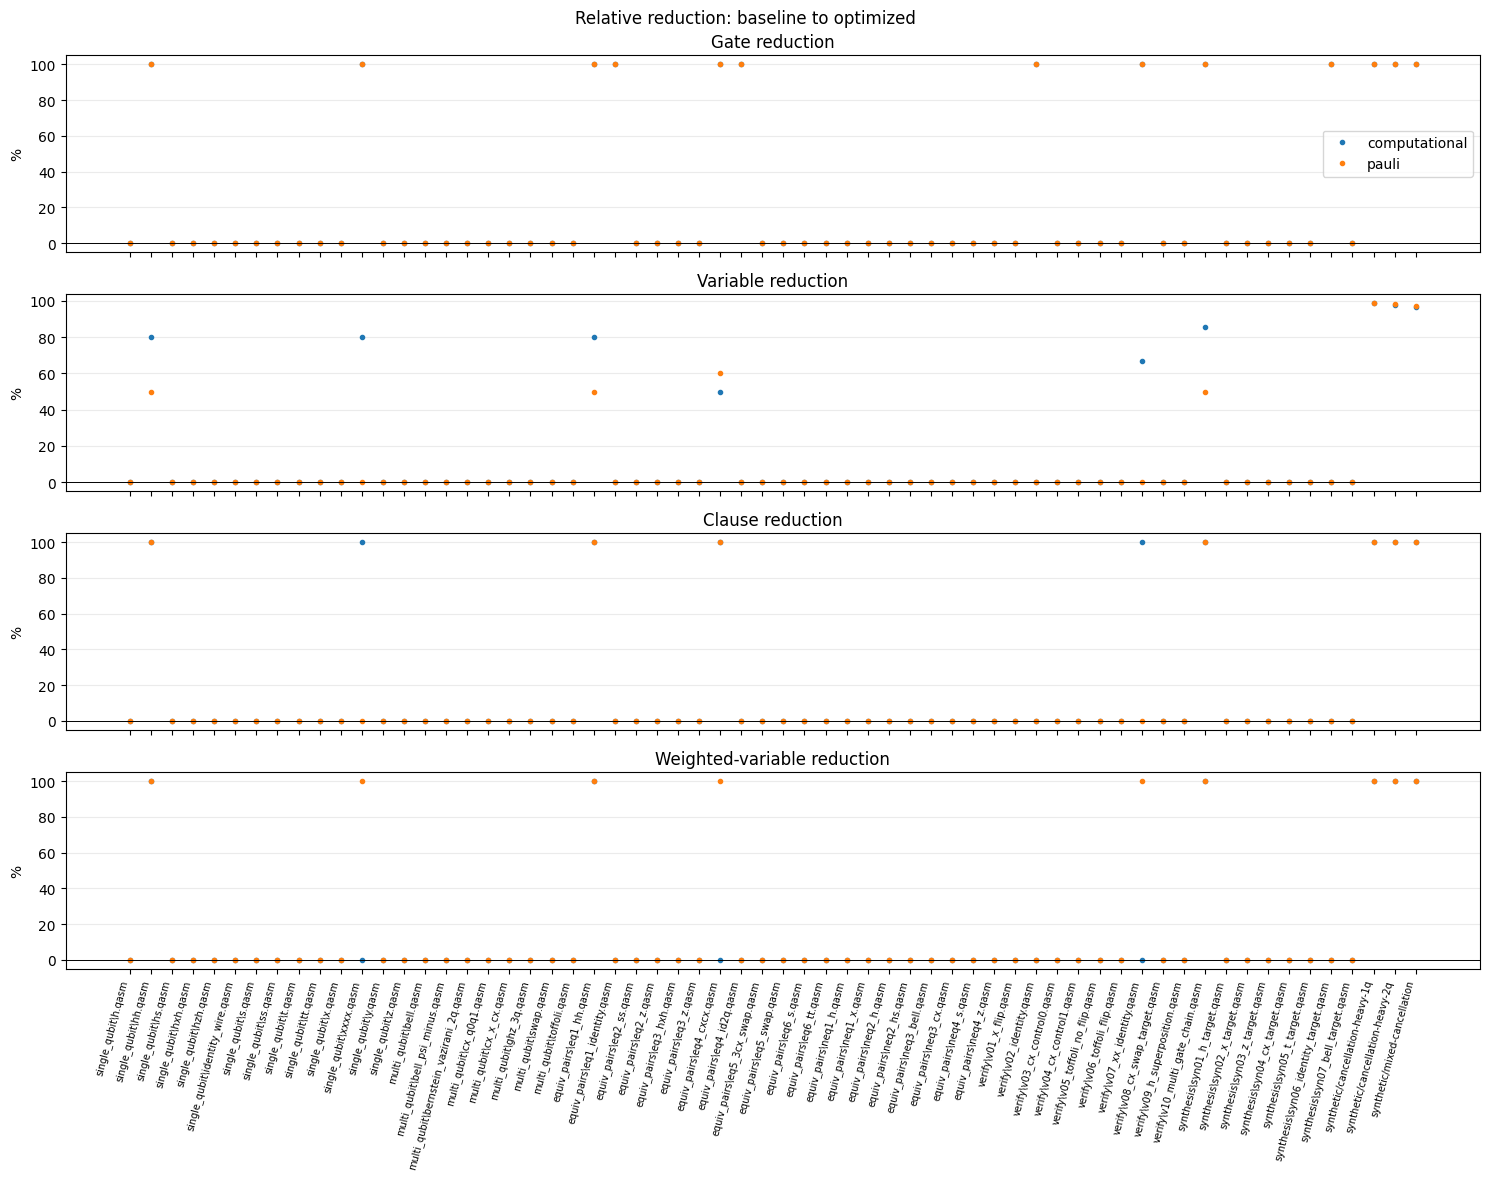

In [4]:
metrics = [
    ('gate_reduction', 'Gate reduction'),
    ('variable_reduction', 'Variable reduction'),
    ('clause_reduction', 'Clause reduction'),
    ('weighted_variable_reduction', 'Weighted-variable reduction'),
]

figure, axes = plt.subplots(len(metrics), 1, figsize=(15, 12), sharex=True)
for axis, (metric, title) in zip(axes, metrics):
    for basis in sorted({row['basis'] for row in rows}):
        subset = [row for row in rows if row['basis'] == basis]
        axis.plot([row['circuit'] for row in subset], [100 * as_float(row, metric) for row in subset], marker='.', linestyle='none', label=basis)
    axis.axhline(0, color='black', linewidth=0.7)
    axis.set_ylabel('%')
    axis.set_title(title)
    axis.grid(axis='y', alpha=0.25)
axes[-1].set_xticklabels([row['circuit'] for row in rows[::2]], rotation=75, ha='right', fontsize=7)
axes[0].legend()
figure.suptitle('Relative reduction: baseline to optimized')
figure.tight_layout()
plt.show()

## Interpretation

The optimizer only removes identity gates and adjacent exact inverse pairs. Therefore zero reduction on a circuit is expected when no such pattern occurs. The synthetic cancellation-heavy circuits estimate the upper bound for this optimization, while the repository fixtures indicate expected real-circuit behavior.